## Importando bibliotecas

In [1]:
#Manipulação dos dados
from joblib import dump, load
import numpy as np
import pandas as pd

#Geração de gráficos
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

#Feature selection
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestRegressor

# Separação de dados em treino, validação e teste
from fast_ml.model_development import train_valid_test_split

from itertools import combinations

In [2]:
#Importando tabela
df = pd.read_csv("../tabelas/tabela_estruturada.csv")
df.head()

,grupo,n_OXA,n_MBL,n_ISAba1,n_ESBL,n_aminoglicosideos,n_sulfa_trimetoprim,n_quinolonas,n_tetraciclina,n_efluxo_adeS,n_polimixinas,n_virulencia_clinica,n_ilha_AbaR,n_resistencia_metais,n_degradacao_aromaticos,MIC_imipenem
0,Sepse,2,1,2,1,3,1,1,0,1,0,1,0,0,0,64.0
1,Ambiental,0,0,0,0,2,0,1,0,0,0,0,0,0,1,0.5
2,Sepse,1,0,2,1,3,2,2,1,1,1,2,1,0,0,8.0
3,Sepse,2,1,2,2,3,1,2,1,1,1,1,1,0,0,64.0
4,Ambiental,1,0,0,0,1,0,0,0,0,0,0,0,2,1,0.5


### Variáveis que melhor explicam os dados

Grupo

In [3]:
#Verificando tipo das colunas e seu index
colunas = [
    'n_OXA', 'n_MBL', 'n_ISAba1', 'n_ESBL',
    'n_aminoglicosideos', 'n_sulfa_trimetoprim',
    'n_quinolonas', 'n_tetraciclina',
    'n_efluxo_adeS', 'n_polimixinas',
    'n_virulencia_clinica', 'n_ilha_AbaR',
    'n_resistencia_metais', 'n_degradacao_aromaticos',
    'MIC_imipenem'
]

df[colunas].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   n_OXA                    1000 non-null   int64  
 1   n_MBL                    1000 non-null   int64  
 2   n_ISAba1                 1000 non-null   int64  
 3   n_ESBL                   1000 non-null   int64  
 4   n_aminoglicosideos       1000 non-null   int64  
 5   n_sulfa_trimetoprim      1000 non-null   int64  
 6   n_quinolonas             1000 non-null   int64  
 7   n_tetraciclina           1000 non-null   int64  
 8   n_efluxo_adeS            1000 non-null   int64  
 9   n_polimixinas            1000 non-null   int64  
 10  n_virulencia_clinica     1000 non-null   int64  
 11  n_ilha_AbaR              1000 non-null   int64  
 12  n_resistencia_metais     1000 non-null   int64  
 13  n_degradacao_aromaticos  1000 non-null   int64  
 14  MIC_imipenem             

In [4]:
#Encontrando a feature que melhor explica o grupo
knn = RandomForestClassifier()
sfs = SequentialFeatureSelector(knn, n_features_to_select=1, direction='backward')

X = df[colunas]
y = df['grupo']

X_selected = sfs.fit_transform(X, y)
X_selected.shape

(1000, 1)

In [5]:
#Coluna que melhor explica o grupo
X.columns[sfs.get_support()]

Index(['n_virulencia_clinica'], dtype='object')

MIC_imipenem

In [6]:
colunas = [
    'n_OXA', 'n_MBL', 'n_ISAba1', 'n_ESBL',
    'n_aminoglicosideos', 'n_sulfa_trimetoprim',
    'n_quinolonas', 'n_tetraciclina',
    'n_efluxo_adeS', 'n_polimixinas',
    'n_virulencia_clinica', 'n_ilha_AbaR',
    
]

In [7]:
#Encontrando a feature que melhor explica a MIC
X = df[colunas]
y = df['MIC_imipenem']

modelo = RandomForestRegressor()

sfs = SequentialFeatureSelector(
    modelo,
    n_features_to_select=1,
    direction='backward'
)

X_selected = sfs.fit_transform(X, y)
X_selected.shape

(1000, 1)

In [8]:
#Coluna que melhor explica a MIC
X.columns[sfs.get_support()]

Index(['n_OXA'], dtype='object')

### Análise bivariada

Quantitativas

In [9]:
#Identificando colunas numéricas
num_columns = df.select_dtypes(include="number").columns
num_columns

Index(['n_OXA', 'n_MBL', 'n_ISAba1', 'n_ESBL', 'n_aminoglicosideos',
       'n_sulfa_trimetoprim', 'n_quinolonas', 'n_tetraciclina',
       'n_efluxo_adeS', 'n_polimixinas', 'n_virulencia_clinica', 'n_ilha_AbaR',
       'n_resistencia_metais', 'n_degradacao_aromaticos', 'MIC_imipenem'],
      dtype='object')

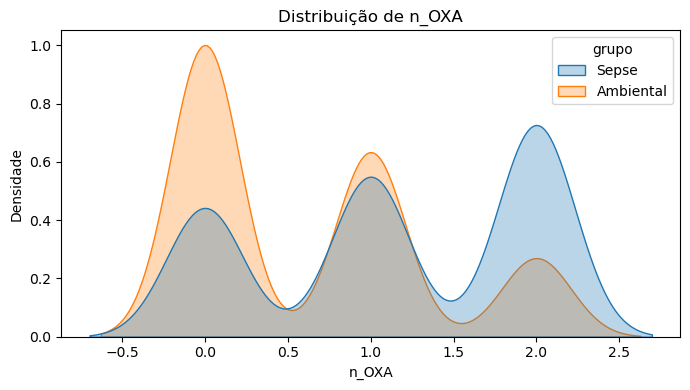

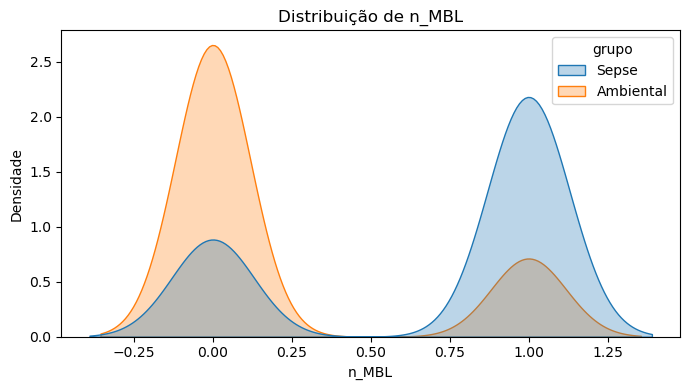

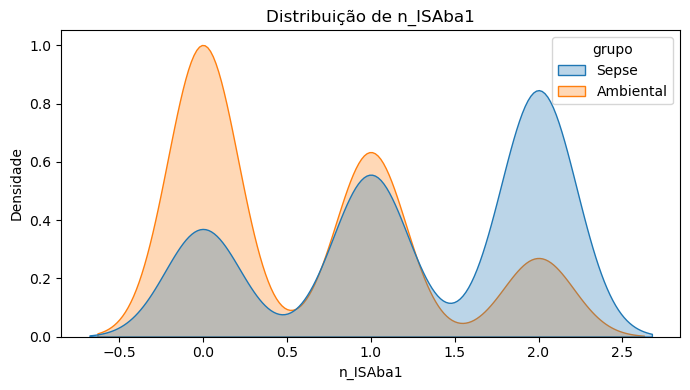

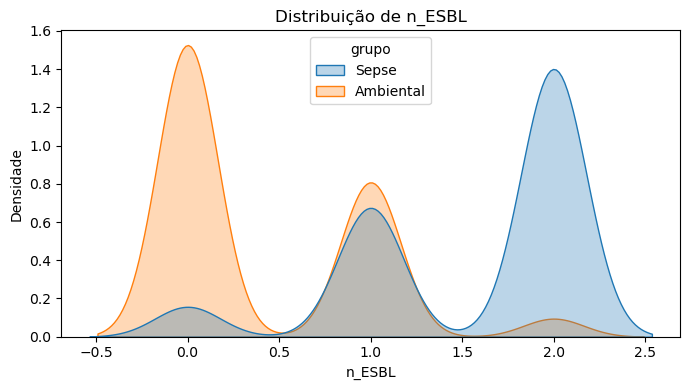

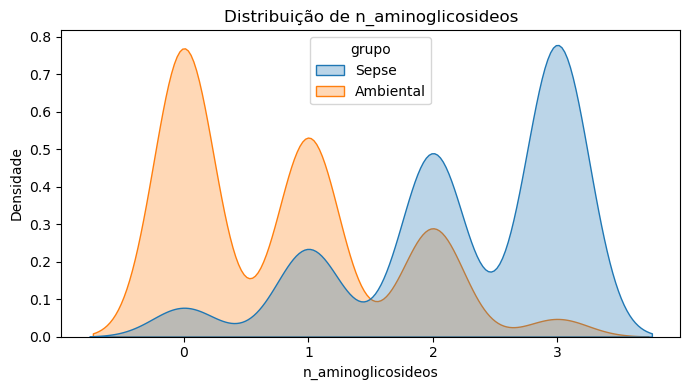

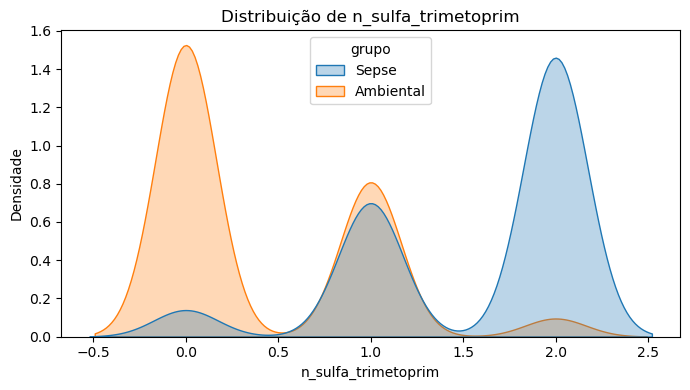

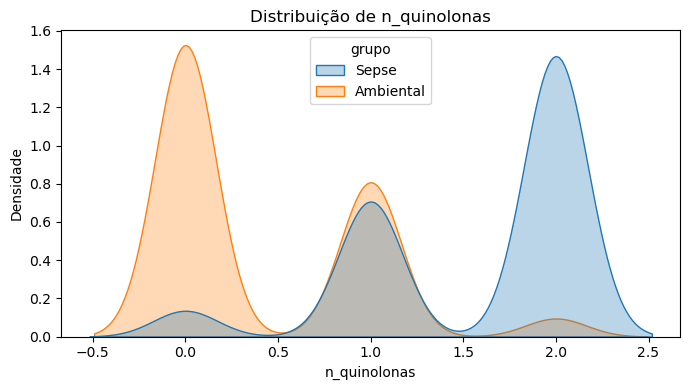

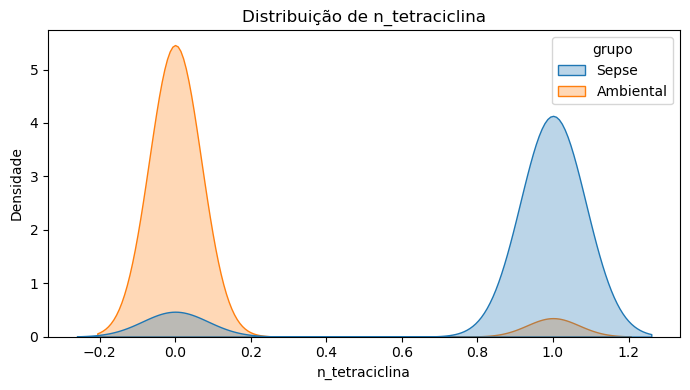

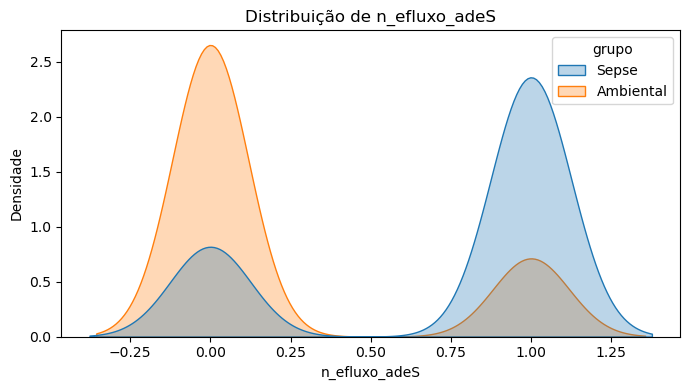

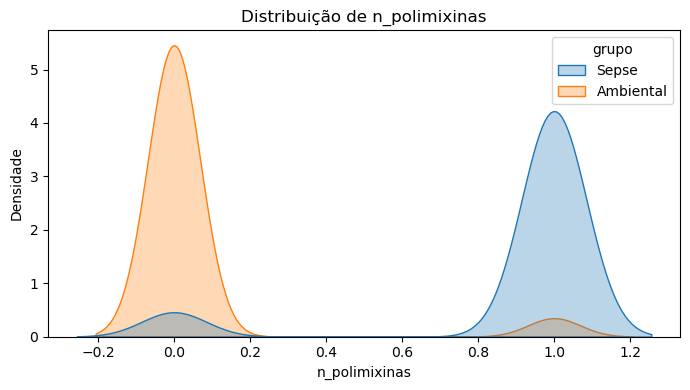

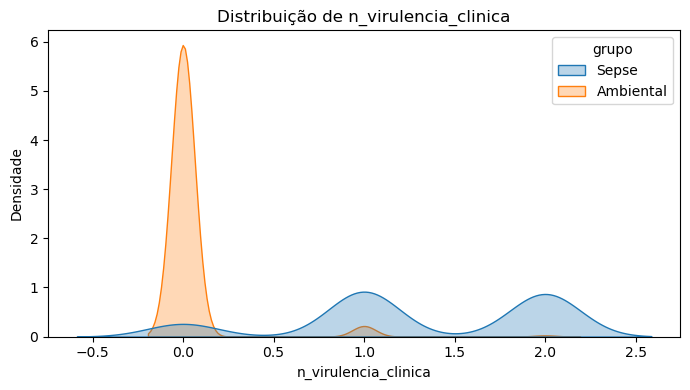

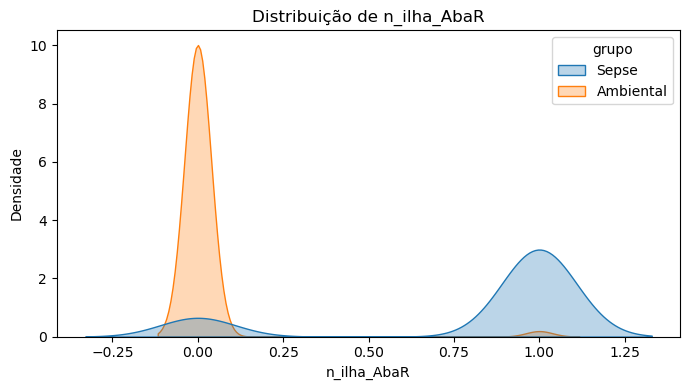

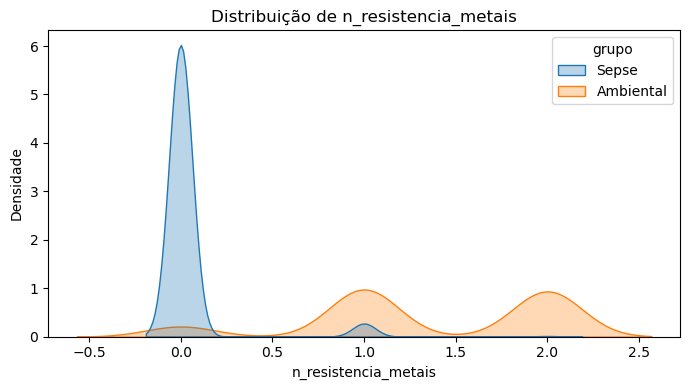

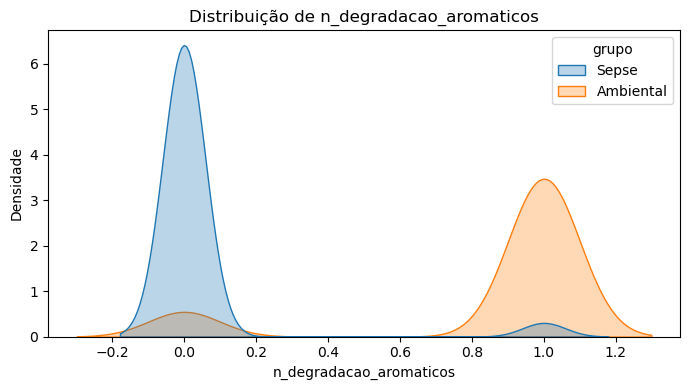

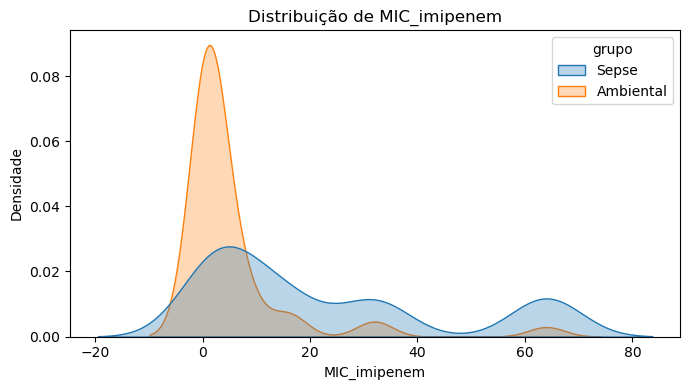

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

for coluna in num_columns:

    plt.figure(figsize=(7, 4))

    sns.kdeplot(
        data=df,
        x=coluna,
        hue="grupo",
        fill=True,
        alpha=0.3,
        common_norm=False
    )

    plt.title(f"Distribuição de {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Densidade")
    plt.tight_layout()
    plt.show()

Identificando features que melhor divide meus dados

In [11]:
#Criando combinações bivariadas
comparacoes = list(combinations(num_columns, 2))
colunas_graficos = list(np.unique(comparacoes))

#Juntando df
df_float = pd.concat([df[colunas_graficos], df[["grupo"]]],axis=1)

df_float.head()

,MIC_imipenem,n_ESBL,n_ISAba1,n_MBL,n_OXA,n_aminoglicosideos,n_degradacao_aromaticos,n_efluxo_adeS,n_ilha_AbaR,n_polimixinas,n_quinolonas,n_resistencia_metais,n_sulfa_trimetoprim,n_tetraciclina,n_virulencia_clinica,grupo
0,64.0,1,2,1,2,3,0,1,0,0,1,0,1,0,1,Sepse
1,0.5,0,0,0,0,2,1,0,0,0,1,0,0,0,0,Ambiental
2,8.0,1,2,0,1,3,0,1,1,1,2,0,2,1,2,Sepse
3,64.0,2,2,1,2,3,0,1,1,1,2,0,1,1,1,Sepse
4,0.5,0,0,0,1,1,1,0,0,0,0,2,0,0,0,Ambiental


In [ ]:
#Identificando as features que melhor separam os grupos
comparacoes = [
    ['n_tetraciclina', 'n_polimixinas'],
    ['n_tetraciclina', 'n_degradacao_aromaticos'],
    ['n_polimixinas', 'n_degradacao_aromaticos']
]
# Seleciona as colunas presentes nas combinações, sem duplicatas
colunas_graficos = list(dict.fromkeys(
    coluna
    for par in comparacoes
    for coluna in par
))

df_float = pd.concat(
    [df[colunas_graficos], df[["grupo"]]],
    axis=1
)

df_float.head()

,n_tetraciclina,n_polimixinas,n_degradacao_aromaticos,n_virulencia_clinica,n_ilha_AbaR,grupo
0,0,0,0,1,0,Sepse
1,0,0,1,0,0,Ambiental
2,1,1,0,2,1,Sepse
3,1,1,0,1,1,Sepse
4,0,0,1,0,0,Ambiental


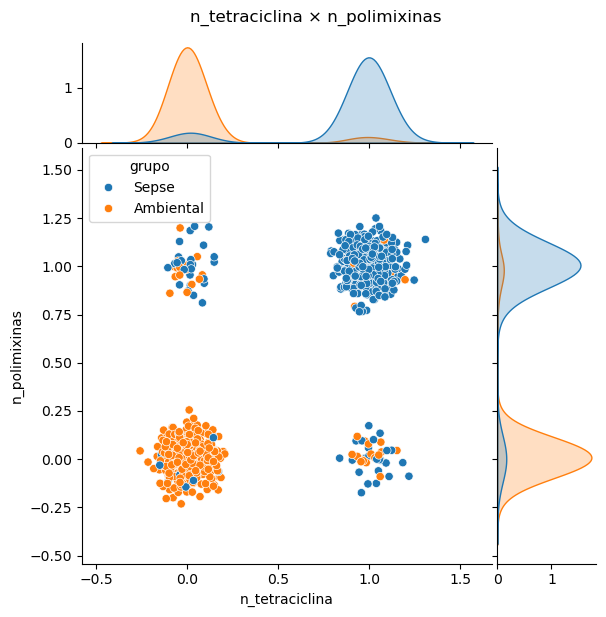

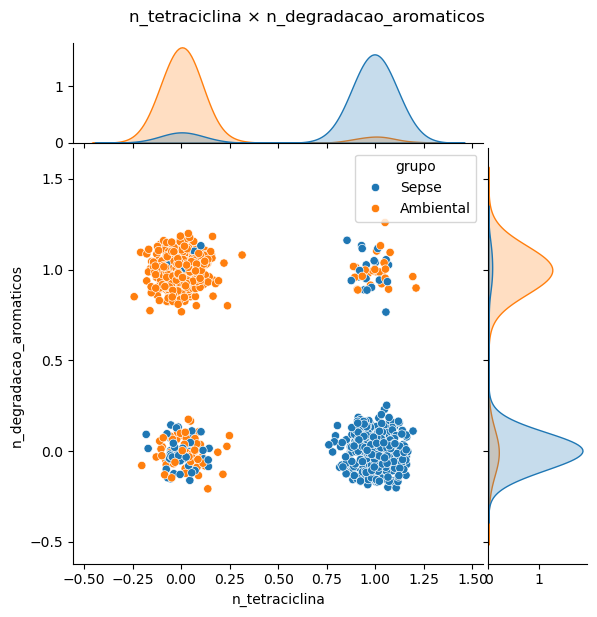

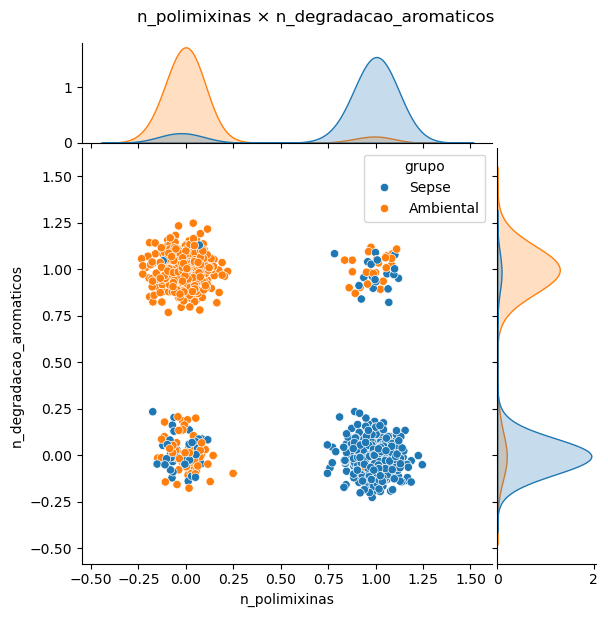

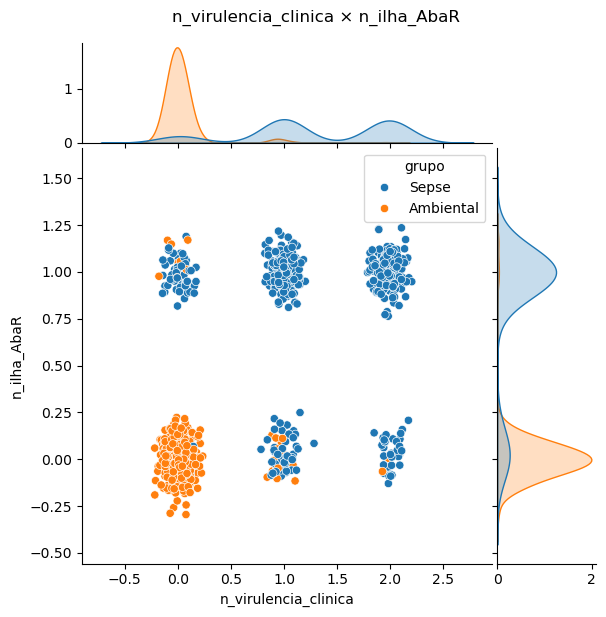

In [13]:
#Gerando gráficos para avaliar as features
np.random.seed(42)

for c1, c2 in comparacoes:

    # Dados apenas para visualização
    dados_plot = df_float[[c1, c2, "grupo"]].dropna().copy()

    # Pequeno jitter para reduzir a sobreposição dos pontos
    dados_plot[c1] += np.random.normal(0, 0.08, len(dados_plot))
    dados_plot[c2] += np.random.normal(0, 0.08, len(dados_plot))

    p = sns.jointplot(
        data=dados_plot,
        x=c1,
        y=c2,
        hue="grupo",
        height=6,
        ratio=4,
        marginal_ticks=True,
        space=0.05
    )

    p.fig.suptitle(f"{c1} × {c2}", y=1.02)
    p.set_axis_labels(xlabel=c1, ylabel=c2)

    plt.show()

Qualitativas

In [14]:
#Criando função quue calcula os indicadores
def calcula_indicadores(
    independente: str,
    dependente: str,
    positivo: str,
    negativo: str,
    df: pd.DataFrame,
    categoria: bool = False,
    bins: int = 5,
) -> pd.DataFrame:
    """
    Calcula indicadores de risco e associação entre uma variável
    independente e uma variável dependente binária.

    Retorna:
        prob       : proporção de cada categoria no conjunto de dados
        risk_event : risco/probabilidade do evento positivo
        odds       : chance (odds) do evento positivo
        odds_ratio : razão de chances em relação ao conjunto total
        log_odd    : logaritmo da odds
        woe        : Weight of Evidence
    """

    df = df.copy()

    # Categorização da variável independente
    if categoria:
        df[independente + "_cat"] = pd.qcut(
            df[independente],
            q=bins,
            duplicates="drop"
        )
        independente = independente + "_cat"

    # Tabela de frequência
    tab = pd.crosstab(
        df[independente],
        df[dependente],
        margins=True
    )

    # Garantir que as duas categorias existam
    if positivo not in tab.columns or negativo not in tab.columns:
        raise ValueError(
            f"As categorias '{positivo}' e '{negativo}' "
            f"não foram encontradas em '{dependente}'."
        )

    # Odds global
    odds_all = tab.loc["All", positivo] / tab.loc["All", negativo]

    # Indicadores
    tab["prob"] = tab["All"] / tab.loc["All", "All"]

    tab["risk_event"] = (
        tab[positivo] / tab["All"]
    )

    tab["odds"] = (
        tab[positivo] / tab[negativo]
    )

    tab["odds_ratio"] = (
        tab["odds"] / odds_all
    )

    tab["log_odd"] = np.log(
        tab[positivo] / tab[negativo]
    )

    tab["woe"] = np.log(
        tab["odds"] / odds_all
    )

    # Substitui infinitos por NaN
    tab = tab.replace([np.inf, -np.inf], np.nan)

    # Informações gerais
    print(f"Flag {negativo}: {tab.loc['All', negativo]}")
    print(f"Flag {positivo}: {tab.loc['All', positivo]}")
    print(f"Total: {tab.loc['All', 'All']}")

    # Remove coluna temporária
    if categoria:
        df.drop(
            columns=[independente],
            inplace=True
        )

    return tab

In [15]:
df.select_dtypes(include="object").head()

,grupo
0,Sepse
1,Ambiental
2,Sepse
3,Sepse
4,Ambiental


In [16]:
#Identificando indicadores através da feature que mais dividiu os grupos
df_indicadores = df.copy()

independente = "n_polimixinas"

resultado = calcula_indicadores(
    independente=independente,
    dependente="grupo",
    positivo="Sepse",
    negativo="Ambiental",
    df=df_indicadores,
)

resultado

Flag Ambiental: 487
Flag Sepse: 513
Total: 1000


grupo,Ambiental,Sepse,All,prob,risk_event,odds,odds_ratio,log_odd,woe
n_polimixinas,,,,,,,,,
0,458,50,508,0.508,0.098425,0.109170,0.103637,-2.214846,-2.266858
1,29,463,492,0.492,0.941057,15.965517,15.156349,2.770431,2.718420
All,487,513,1000,1.000,0.513000,1.053388,1.000000,0.052012,0.000000


In [17]:
X_train, y_train, X_valid, y_valid, X_test, y_test = train_valid_test_split(
    df,
    target="grupo",
    train_size=0.7,
    valid_size=0.2,
    test_size=0.1,
    random_state=42,
)

print("-" * 10)
print(f"X_train: {X_train.shape}")
print(f"X_valid: {X_valid.shape}")
print(f"X_test: {X_test.shape}")
print("-" * 10)
print(f"y_train: {y_train.shape}")
print(f"y_valid: {y_valid.shape}")
print(f"y_test: {y_test.shape}")

----------
X_train: (700, 15)
X_valid: (200, 15)
X_test: (100, 15)
----------
y_train: (700,)
y_valid: (200,)
y_test: (100,)


In [18]:
#Salvando dataframes separadas
X_train.to_csv("../tabelas/tabelas_finais/X/X_train.csv", index=False)
X_valid.to_csv("../tabelas/tabelas_finais/X/X_valid.csv", index=False)
X_test.to_csv("../tabelas/tabelas_finais/X/X_test.csv", index=False)

y_train.to_csv("../tabelas/tabelas_finais/y/y_train.csv", index=False)
y_valid.to_csv("../tabelas/tabelas_finais/y/y_valid.csv", index=False)
y_test.to_csv("../tabelas/tabelas_finais/y/y_test.csv", index=False)

OSError: Cannot save file into a non-existent directory: '../tabelas/tabelas_finais/X'